Neste projeto vamos trabalhar com uma base de dados contendo informações sobre terremotos registrados em diferentes partes do mundo, incluindo características como magnitude, profundidade e localização geográfica e outros indicadores sísmicos relevantes. A partir desses dados, construiremos um modelo de Machine Learning capaz de prever se um determinado terremoto gerou ou não um tsunami.

Ao final você terá desenvolvido um projeto completo de classificação supervisionada, entendendo na prática como a inteligência Artificial pode ser aplicada para trasnformar dados sísmicos em informações úteis para apoiar sistemas modernos de monitoramento e prevnção de desastres naturais.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import warnings
plt.rcParams['figure.figsize'] = (10, 5)
plt.style.use('fivethirtyeight')
warnings.filterwarnings('ignore')

In [9]:
df = pd.read_csv('earthquake_data_tsunami.csv',encoding = 'Latin-1')
df.head(3)

,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
0,7.0,8,7,768,117,0.509,17.0,14.0,-9.7963,159.596,2022,11,1
1,6.9,4,4,735,99,2.229,34.0,25.0,-4.9559,100.738,2022,11,0
2,7.0,3,3,755,147,3.125,18.0,579.0,-20.0508,-178.346,2022,11,1


In [7]:
df.shape

(782, 13)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   magnitude  782 non-null    float64
 1   cdi        782 non-null    int64  
 2   mmi        782 non-null    int64  
 3   sig        782 non-null    int64  
 4   nst        782 non-null    int64  
 5   dmin       782 non-null    float64
 6   gap        782 non-null    float64
 7   depth      782 non-null    float64
 8   latitude   782 non-null    float64
 9   longitude  782 non-null    float64
 10  Year       782 non-null    int64  
 11  Month      782 non-null    int64  
 12  tsunami    782 non-null    int64  
dtypes: float64(6), int64(7)
memory usage: 79.6 KB


In [10]:
df.describe()

,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
count,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000
mean,6.941125,4.333760,5.964194,870.108696,230.250639,1.325757,25.038990,75.883199,3.538100,52.609199,2012.280051,6.563939,0.388747
std,0.445514,3.169939,1.462724,322.465367,250.188177,2.218805,24.225067,137.277078,27.303429,117.898886,6.099439,3.507866,0.487778
min,6.500000,0.000000,1.000000,650.000000,0.000000,0.000000,0.000000,2.700000,-61.848400,-179.968000,2001.000000,1.000000,0.000000
25%,6.600000,0.000000,5.000000,691.000000,0.000000,0.000000,14.625000,14.000000,-14.595600,-71.668050,2007.000000,3.250000,0.000000
50%,6.800000,5.000000,6.000000,754.000000,140.000000,0.000000,20.000000,26.295000,-2.572500,109.426000,2013.000000,7.000000,0.000000
75%,7.100000,7.000000,7.000000,909.750000,445.000000,1.863000,30.000000,49.750000,24.654500,148.941000,2017.000000,10.000000,1.000000
max,9.100000,9.000000,9.000000,2910.000000,934.000000,17.654000,239.000000,670.810000,71.631200,179.662000,2022.000000,12.000000,1.000000


In [11]:
df.isnull().sum()

magnitude    0
cdi          0
mmi          0
sig          0
nst          0
dmin         0
gap          0
depth        0
latitude     0
longitude    0
Year         0
Month        0
tsunami      0
dtype: int64

In [12]:
df['tsunami'].value_counts().sort_index()

tsunami
0    478
1    304
Name: count, dtype: int64

In [14]:
counts = df['tsunami'].value_counts(normalize=True).round(2) * 100

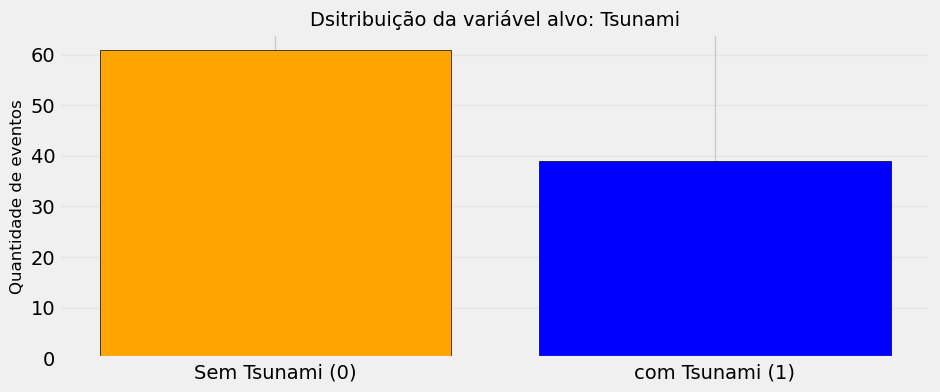

In [16]:
plt.figure(figsize=(10,4))
plt.bar(
    ['Sem Tsunami (0)', 'com Tsunami (1)'],
    counts.values,
    color=['orange', 'blue'],
    edgecolor='black'
)
plt.title('Dsitribuição da variável alvo: Tsunami', fontsize=14)
plt.ylabel('Quantidade de eventos', fontsize=12)
plt.grid(axis='y', alpha=0.3)

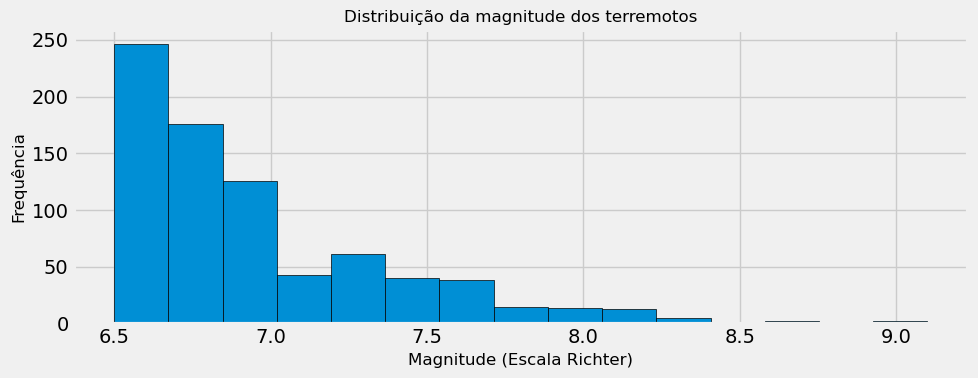

In [19]:
plt.figure(figsize=(10,4))
plt.hist(df['magnitude'], bins=15, edgecolor='black')
plt.title('Distribuição da magnitude dos terremotos', fontsize=12)
plt.xlabel('Magnitude (Escala Richter)', fontsize=12)
plt.ylabel('Frequência', fontsize=12)
plt.tight_layout()
plt.show()

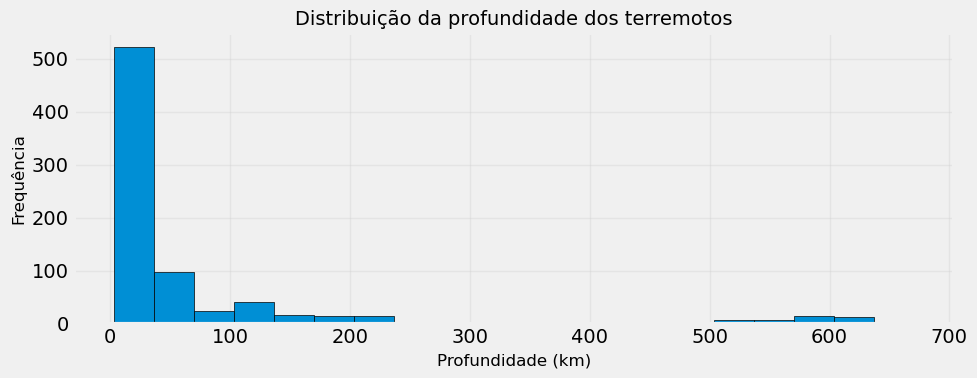

In [21]:
plt.figure(figsize=(10,4))
plt.hist(df['depth'], bins=20, edgecolor='black')
plt.title('Distribuição da profundidade dos terremotos', fontsize=14)
plt.xlabel('Profundidade (km)', fontsize=12)
plt.ylabel('Frequência', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
!apt-get -q install -y libproj-dev proj-data proj-bin libgeos-dev
!pip install -q cartopy

E: Não foi possível abrir arquivo de trava /var/lib/dpkg/lock-frontend - open (13: Permissão negada)
E: Impossível adquirir a trava da interface do dpkg (/var/lib/dpkg/lock-frontend), você é root?

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [23]:
pip install --upgrade pip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 2.1 MB/s  0:00:01 eta 0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 26.2.1
    Uninstalling pip-26.2.1:
      Successfully uninstalled pip-26.2.1
Note: you may need to restart the kernel to use updated packages.


In [24]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

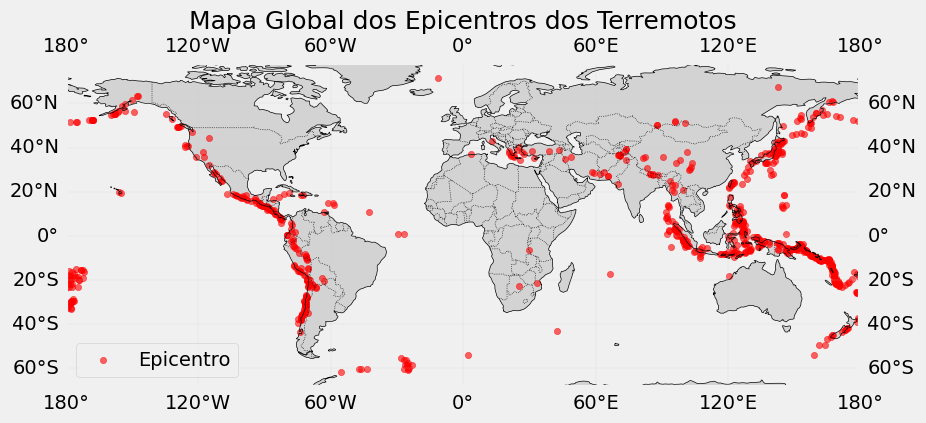

In [26]:
plt.figure(figsize=(10,4))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
plt.scatter(
    df['longitude'],
    df['latitude'],
    s=20,
    c='red',
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label='Epicentro'
        )
plt.title("Mapa Global dos Epicentros dos Terremotos", fontsize=18)
plt.legend()
plt.show()
